In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df = pd.read_excel("../data/Online Retail.xlsx")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [5]:
df.shape

(541909, 8)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [7]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(5268)

In [9]:
df = df.drop_duplicates()

In [10]:
df = df.dropna(subset=["CustomerID"])

In [11]:
df["InvoiceNo"] = df["InvoiceNo"].astype(str)

df = df[~df["InvoiceNo"].str.startswith("C")]

In [12]:
df = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
]

In [13]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

In [14]:
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

In [15]:
print("Rows and columns:", df.shape)

print("Missing values:")
print(df.isnull().sum())

print("Duplicates:", df.duplicated().sum())

df.head()

Rows and columns: (392692, 9)
Missing values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
Revenue        0
dtype: int64
Duplicates: 0


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [16]:
df.shape

(392692, 9)

In [17]:
df[["Quantity", "UnitPrice", "Revenue"]].head(10)

,Quantity,UnitPrice,Revenue
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34
5,2,7.65,15.30
6,6,4.25,25.50
7,6,1.85,11.10
8,6,1.85,11.10
9,32,1.69,54.08


In [18]:
total_revenue = df["Revenue"].sum()

print("Total Revenue:", total_revenue)

Total Revenue: 8887208.894


In [19]:
total_orders = df["InvoiceNo"].nunique()

print("Total Orders:", total_orders)

Total Orders: 18532


In [20]:
total_orders = df["CustomerID"].nunique()

print("Total Customers:", total_orders)

Total Customers: 4338


In [21]:
aov = total_revenue / total_orders

print("Average Order Value:", round(aov, 2))

Average Order Value: 2048.69


In [22]:
top_products = (
    df.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products)

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        77916
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54319
JUMBO BAG RED RETROSPOT               46078
WHITE HANGING HEART T-LIGHT HOLDER    36706
ASSORTED COLOUR BIRD ORNAMENT         35263
PACK OF 72 RETROSPOT CAKE CASES       33670
POPCORN HOLDER                        30919
RABBIT NIGHT LIGHT                    27153
MINI PAINT SET VINTAGE                26076
Name: Quantity, dtype: int64


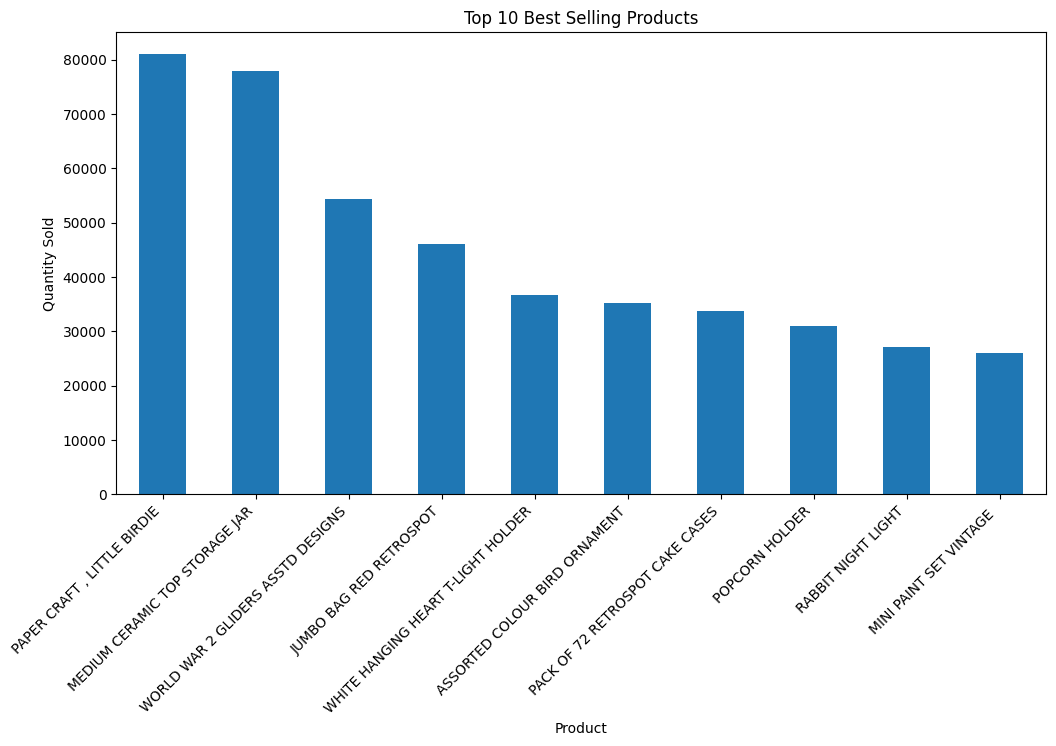

In [23]:
plt.figure(figsize=(12, 6))

top_products.plot(kind="bar")

plt.title("Top 10 Best Selling Products")
plt.xlabel("Product")
plt.ylabel("Quantity Sold")
plt.xticks(rotation=45, ha="right")

plt.show()

In [24]:
country_sales = (
    df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(country_sales)

Country
United Kingdom    7285024.644
Netherlands        285446.340
EIRE               265262.460
Germany            228678.400
France             208934.310
Australia          138453.810
Spain               61558.560
Switzerland         56443.950
Belgium             41196.340
Sweden              38367.830
Name: Revenue, dtype: float64


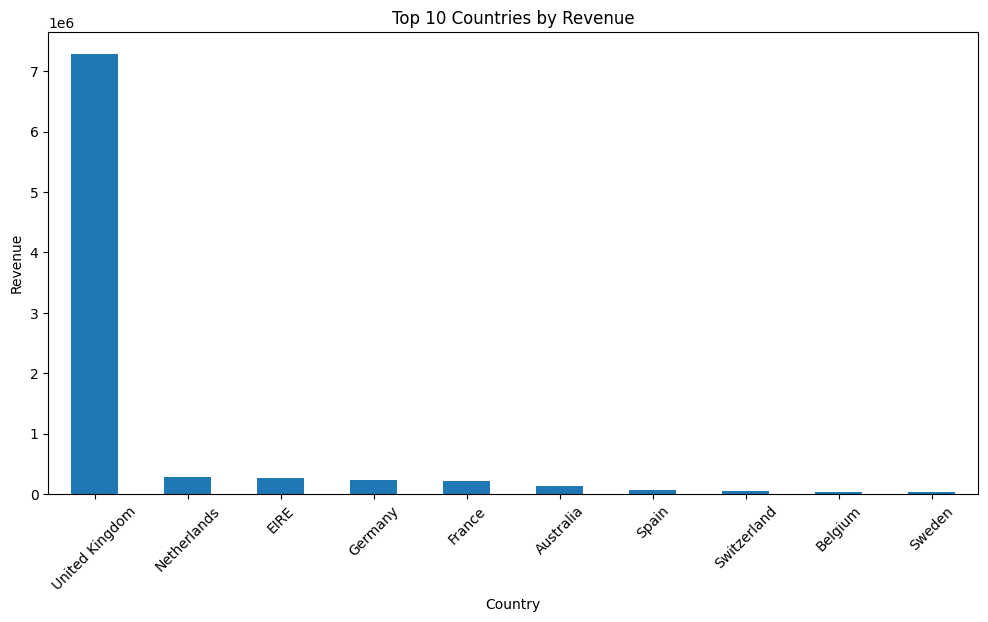

In [25]:
plt.figure(figsize=(12, 6))

country_sales.plot(kind="bar")

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Country")
plt.ylabel("Revenue")

plt.xticks(rotation=45)

plt.show()

In [26]:
df["Month"] = df["InvoiceDate"].dt.month
df["Year"] = df["InvoiceDate"].dt.year

df["YearMonth"] = df["InvoiceDate"].dt.to_period("M")

In [27]:
monthly_sales = df.groupby(
    "YearMonth"
)["Revenue"].sum()

print(monthly_sales)

YearMonth
2010-12     570422.730
2011-01     568101.310
2011-02     446084.920
2011-03     594081.760
2011-04     468374.331
2011-05     677355.150
2011-06     660046.050
2011-07     598962.901
2011-08     644051.040
2011-09     950690.202
2011-10    1035642.450
2011-11    1156205.610
2011-12     517190.440
Freq: M, Name: Revenue, dtype: float64


In [28]:
best_month = monthly_sales.idxmax()

best_revenue = monthly_sales.max()

print("Best Month:", best_month)
print("Highest Revenue:", best_revenue)

Best Month: 2011-11
Highest Revenue: 1156205.61


In [29]:
worst_month = monthly_sales.idxmin()

worst_revenue = monthly_sales.min()

print("Lowest Month:", worst_month)
print("Lowest Revenue:", worst_revenue)

Lowest Month: 2011-02
Lowest Revenue: 446084.92


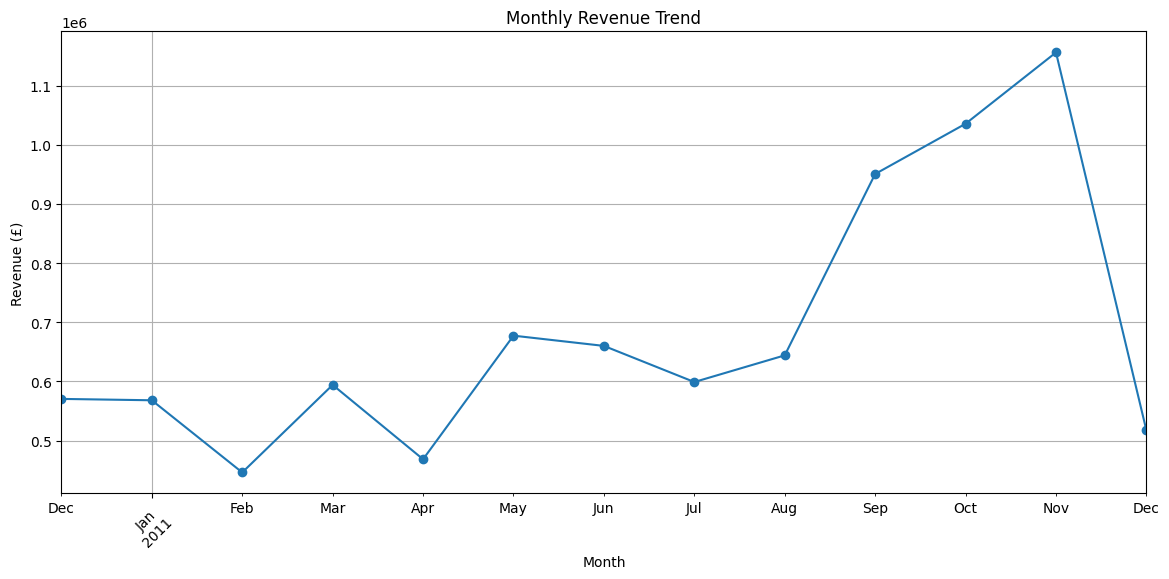

In [30]:
plt.figure(figsize=(14, 6))

monthly_sales.plot(
    kind="line",
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.grid(True)

plt.xticks(rotation=45)

plt.show()

In [31]:
top_revenue_products = (
    df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_revenue_products)

Description
PAPER CRAFT , LITTLE BIRDIE           168469.60
REGENCY CAKESTAND 3 TIER              142264.75
WHITE HANGING HEART T-LIGHT HOLDER    100392.10
JUMBO BAG RED RETROSPOT                85040.54
MEDIUM CERAMIC TOP STORAGE JAR         81416.73
POSTAGE                                77803.96
PARTY BUNTING                          68785.23
ASSORTED COLOUR BIRD ORNAMENT          56413.03
Manual                                 53419.93
RABBIT NIGHT LIGHT                     51251.24
Name: Revenue, dtype: float64


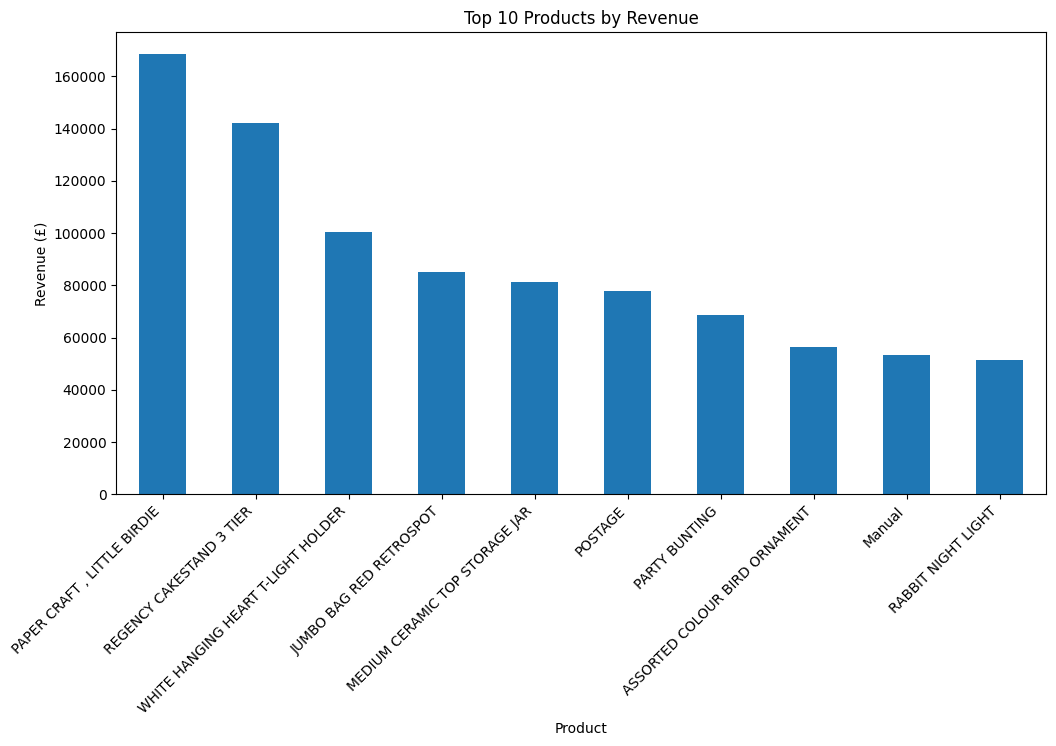

In [32]:
plt.figure(figsize=(12, 6))

top_revenue_products.plot(kind="bar")

plt.title("Top 10 Products by Revenue")
plt.xlabel("Product")
plt.ylabel("Revenue (£)")

plt.xticks(rotation=45, ha="right")

plt.show()

In [33]:
latest_date = df["InvoiceDate"].max()

print("Latest Transaction Date:", latest_date)

Latest Transaction Date: 2011-12-09 12:50:00


In [34]:
import datetime as dt

reference_date = latest_date + dt.timedelta(days=1)

print(reference_date)

2011-12-10 12:50:00


In [35]:
rfm = df.groupby("CustomerID").agg({

    "InvoiceDate": lambda x: (
        reference_date - x.max()
    ).days,

    "InvoiceNo": "nunique",

    "Revenue": "sum"

})

In [36]:
rfm.columns = [
    "Recency",
    "Frequency",
    "Monetary"
]

rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [37]:
rfm["R_score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
)

rfm["F_score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
)

rfm["M_score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
)

In [38]:
rfm["RFM_Score"] = (
    rfm["R_score"].astype(str) +
    rfm["F_score"].astype(str) +
    rfm["M_score"].astype(str)
)

In [39]:
def segment_customer(row):

    if row["R_score"] >= 4 and row["F_score"] >= 4:
        return "Champions"

    elif row["R_score"] >= 3 and row["F_score"] >= 3:
        return "Loyal Customers"

    elif row["R_score"] <= 2:
        return "At Risk"

    else:
        return "Regular Customers"


rfm["Segment"] = rfm.apply(
    segment_customer,
    axis=1
)

In [40]:
segment_counts = rfm["Segment"].value_counts()

print(segment_counts)

Segment
At Risk              1735
Champions            1121
Loyal Customers       821
Regular Customers     661
Name: count, dtype: int64


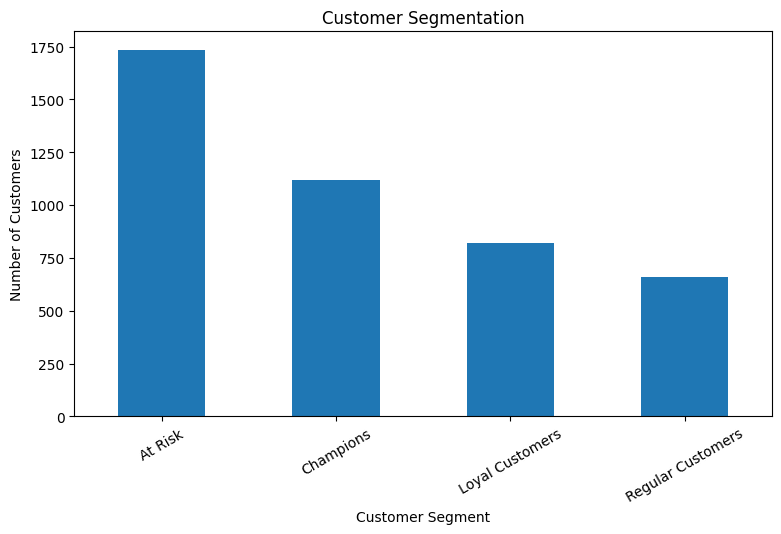

In [41]:
plt.figure(figsize=(9, 5))

segment_counts.plot(
    kind="bar",
    title="Customer Segmentation"
)

plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")

plt.xticks(rotation=30)

plt.show()

In [42]:
segment_revenue = rfm.groupby(
    "Segment"
)["Monetary"].sum().sort_values(ascending=False)

print(segment_revenue)

Segment
Champions            5857798.930
Loyal Customers      1380847.521
At Risk              1347715.723
Regular Customers     300846.720
Name: Monetary, dtype: float64


In [43]:
print(rfm.head())
print(rfm["Segment"].value_counts())
print(segment_revenue)

            Recency  Frequency  Monetary R_score F_score M_score RFM_Score  \
CustomerID                                                                   
12346.0         326          1  77183.60       1       1       5       115   
12347.0           2          7   4310.00       5       5       5       555   
12348.0          75          4   1797.24       2       4       4       244   
12349.0          19          1   1757.55       4       1       4       414   
12350.0         310          1    334.40       1       1       2       112   

                      Segment  
CustomerID                     
12346.0               At Risk  
12347.0             Champions  
12348.0               At Risk  
12349.0     Regular Customers  
12350.0               At Risk  
Segment
At Risk              1735
Champions            1121
Loyal Customers       821
Regular Customers     661
Name: count, dtype: int64
Segment
Champions            5857798.930
Loyal Customers      1380847.521
At Risk          

In [44]:
df.to_csv(
    "../data/cleaned_online_retail.csv",
    index=False
)

In [45]:
rfm.to_csv("../data/customer_rfm.csv")